# Summarize frozen vs full training runs

Thin notebook wrapper around `summarize_runs.py`. Configure the run paths below, then run all
cells: the statistics table prints to the output and the two summary plots render inline.

All logic lives in `summarize_runs.py` (single source of truth, shared with the CLI script).

In [1]:
%matplotlib inline
import summarize_runs as sr

# --- configure your runs here ---
FROZEN_PATHS = [
    '../dynapse_results/mnist1d/frozen/201172_0/',
    '../dynapse_results/mnist1d/frozen/201172_1/',
    '../dynapse_results/mnist1d/frozen/201172_2/',
    '../dynapse_results/mnist1d/frozen/201173_0/',
    '../dynapse_results/mnist1d/frozen/201173_1/',
    '../dynapse_results/mnist1d/frozen/201173_2/',
    '../dynapse_results/mnist1d/frozen/201174_0/',
    '../dynapse_results/mnist1d/frozen/201174_1/',
    '../dynapse_results/mnist1d/frozen/201174_2/',
]
FULL_PATHS = [
    '../dynapse_results/mnist1d/full/201172_0/',
    '../dynapse_results/mnist1d/full/201172_1/',
    '../dynapse_results/mnist1d/full/201172_2/',
    '../dynapse_results/mnist1d/full/201173_0/',
    '../dynapse_results/mnist1d/full/201173_1/',
    '../dynapse_results/mnist1d/full/201173_2/',
    '../dynapse_results/mnist1d/full/201174_0/',
    '../dynapse_results/mnist1d/full/201174_1/',
    '../dynapse_results/mnist1d/full/201174_2/',
    '../dynapse_results/mnist1d/full/201175_0/',
    '../dynapse_results/mnist1d/full/201175_1/',
    '../dynapse_results/mnist1d/full/201175_2/',
]
ROLLING_WINDOW = 100  # smoothing for the training curves only


Summary: 9 frozen run(s), 12 full run(s)
Improvement pairs (exact chip+seed match): 9

Per-group statistics across runs:
                 Metric            Eval  Group  n   Mean    Std    Min    Max
Classification accuracy Best validation Frozen  9 0.5409 0.0378 0.4880 0.6140
Classification accuracy Best validation   Full 12 0.7423 0.0218 0.7000 0.7800
Classification accuracy            Test Frozen  9 0.5061 0.0330 0.4600 0.5600
Classification accuracy            Test   Full 12 0.7020 0.0283 0.6720 0.7720
      Target error [Hz] Best validation Frozen  9 5.6285 0.1264 5.4362 5.8389
      Target error [Hz] Best validation   Full 12 4.9115 0.0667 4.8042 5.0116
      Target error [Hz]            Test Frozen  9 5.7217 0.1206 5.5117 5.9175
      Target error [Hz]            Test   Full 12 4.9717 0.0725 4.8182 5.1170

Frozen -> full improvement (positive = full is better):
                 Metric            Eval  pairs Mean improvement    Std    Min    Max
      Target error [Hz]           

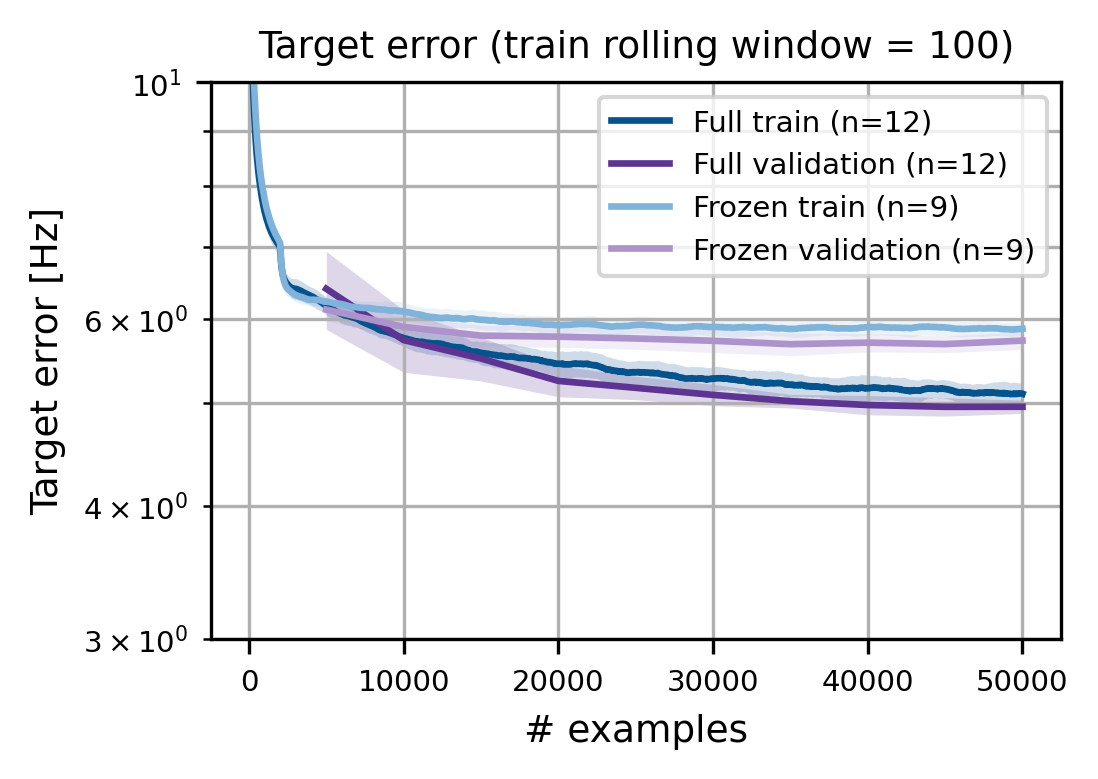

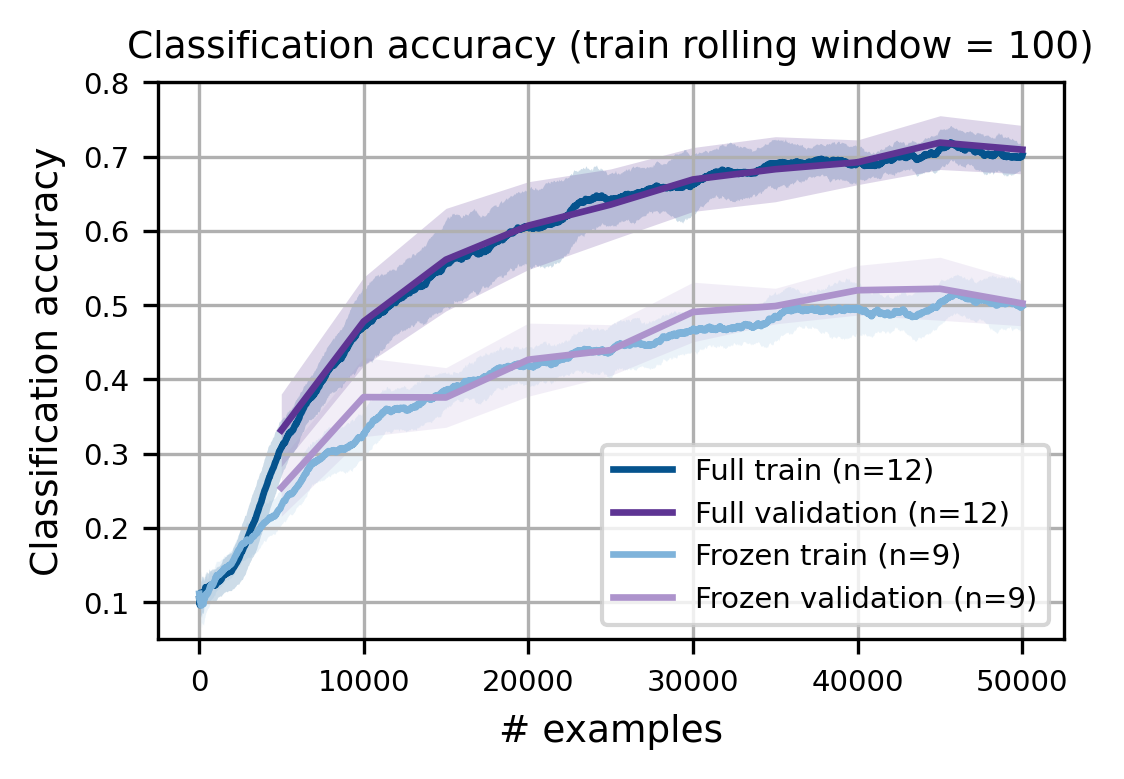

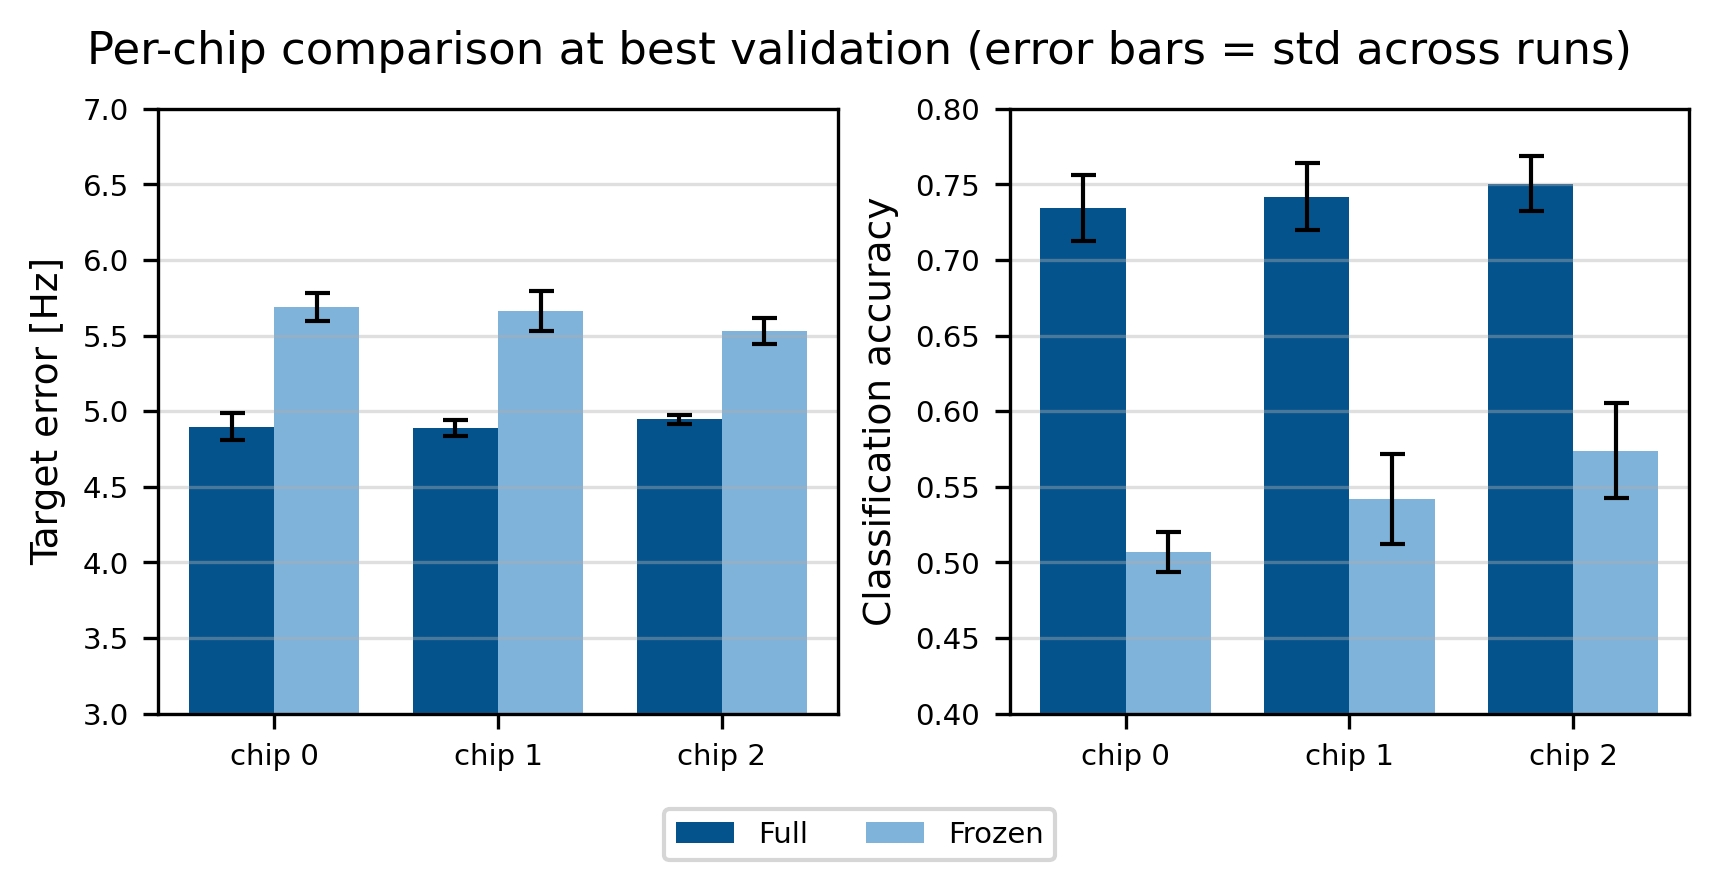

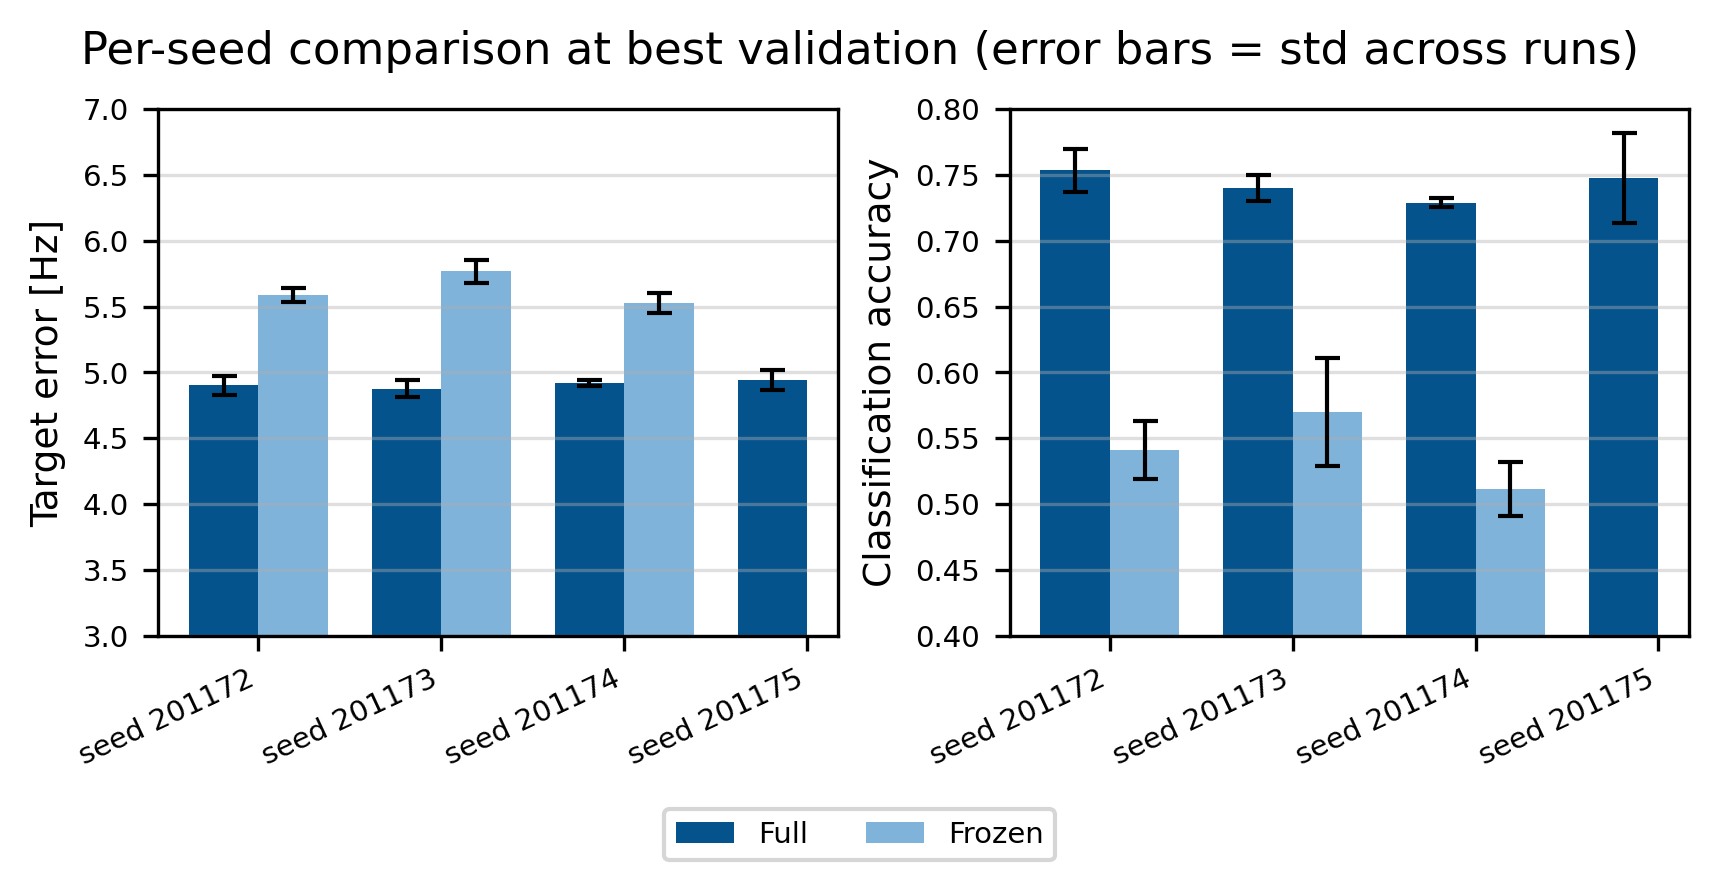

In [2]:
# Load, compute statistics, print the table, and render both plots inline.
# save=False keeps it notebook-only; set save=True to also write PDF/PNG files.
# frozen_skipped_initial_val=True: these frozen runs were recorded without the
# index-0 pre-training validation, so trim the trailing zero row and shift the
# validation curve by one (see summarize_runs.load_run). Set False if re-recorded
# with the initial validation included.
results = sr.summarize(
    sr._expand(FROZEN_PATHS),
    sr._expand(FULL_PATHS),
    rolling_window=ROLLING_WINDOW,
    save=False,
    show=True,
    frozen_skipped_initial_val=True,
)

In [3]:
# The returned dict exposes everything for further analysis, e.g.:
#   results['frozen_stats'], results['full_stats'], results['improvements']
#   results['frozen_runs'][0]  # per-run curves and scalars
import pandas as pd
pd.DataFrame(results['improvements']['pairs'], columns=['chip', 'seed'])

,chip,seed
0,0,201172
1,0,201173
2,0,201174
3,1,201172
4,1,201173
5,1,201174
6,2,201172
7,2,201173
8,2,201174
